In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import ast

print(f'NumPy   version: {np.__version__}')
print(f'pandas  version: {pd.__version__}')
print('Imports successful.')

NumPy   version: 2.1.3
pandas  version: 2.2.3
Imports successful.


In [2]:
def extract_anomaly_windows(anomaly_labels):
    """Converts binary label array to list of (start, end) tuples."""
    windows   = []
    in_window = False
    start     = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start     = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows


def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Injects noise or blackout into a localized index window."""
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]
    if mode == 'noise':
        injection = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += injection
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'.")
    return poisoned_data


print('Carry-forward functions loaded.')

Carry-forward functions loaded.


In [3]:
def make_synthetic_skab_file(filepath, n_rows, anomaly_windows, seed=0):
    """
    Generates a synthetic SKAB-format CSV with 8 sensor columns,
    an anomaly label column, and a changepoint column.
    """
    np.random.seed(seed)
    t       = np.linspace(0, 50, n_rows)
    sensors = {}
    names   = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
                'Pressure', 'Temperature', 'Thermocouple',
                'Voltage', 'Volume Flow RateRMS']
    for i, name in enumerate(names):
        sensors[name] = np.sin(t * (i + 1)) + np.random.normal(0, 0.05, n_rows)

    labels      = np.zeros(n_rows, dtype=int)
    changepoint = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e]    = 1
        changepoint[s] = 1

    idx = pd.date_range('2020-01-01', periods=n_rows, freq='1s')
    df  = pd.DataFrame(sensors, index=idx)
    df.index.name = 'datetime'
    df['anomaly']     = labels
    df['changepoint'] = changepoint
    df.to_csv(filepath, sep=';')


# Create synthetic dataset: 5 files, varying lengths and anomaly profiles
synth_dir = Path('synthetic_alldata')
synth_dir.mkdir(exist_ok=True)

files_spec = [
    ('1.csv', 800,  [(150, 230), (500, 580)]),
    ('2.csv', 1000, [(200, 350)]),
    ('3.csv', 600,  []),
    ('4.csv', 900,  [(100, 160), (400, 480), (700, 750)]),
    ('5.csv', 750,  [(300, 420)]),
]

for fname, n_rows, windows in files_spec:
    make_synthetic_skab_file(synth_dir / fname, n_rows, windows)

actual = sorted(synth_dir.glob('*.csv'))
print(f'Generated {len(actual)} synthetic SKAB files in {synth_dir}/')
for f in actual:
    df = pd.read_csv(f, sep=';', index_col='datetime')
    n_anom = df['anomaly'].sum()
    print(f'  {f.name}: {len(df)} rows, {n_anom} anomaly rows')

Generated 5 synthetic SKAB files in synthetic_alldata/
  1.csv: 800 rows, 160 anomaly rows
  2.csv: 1000 rows, 150 anomaly rows
  3.csv: 600 rows, 0 anomaly rows
  4.csv: 900 rows, 190 anomaly rows
  5.csv: 750 rows, 120 anomaly rows


In [7]:
def process_skab_file(filepath, mode='noise', variance=2.5, seed=42):
    """
    Loads one SKAB CSV, extracts anomaly windows, injects a noise profile,
    and returns the contaminated sensor array with metadata.

    Parameters
    ----------
    filepath : Path or str
    mode     : str — 'noise' or 'blackout'
    variance : float — std dev for mode='noise'
    seed     : int — random seed for reproducibility

    Returns
    -------
    dict with keys: filename, X_clean, X_contaminated, windows,
                    n_windows, n_rows, n_features
    """
    # TODO: Load the CSV with sep=';', index_col='datetime', parse_dates=True


    # TODO: Separate sensor columns (exclude 'anomaly' and 'changepoint')
    # TODO: Extract X (sensor values as float) and labels (anomaly column as int)

    # TODO: Call extract_anomaly_windows() on labels
    # TODO: Set np.random.seed(seed)
    # TODO: Copy X and apply inject_noise_profile() for each window

    # TODO: Return the dict — see docstring for keys
# Load CSV
def process_skab_file(filepath, mode='noise', variance=2.5, seed=42):

    df = pd.read_csv(
        filepath,
        sep=';',
        index_col='datetime',
        parse_dates=True
    )

    sensor_cols = [
        c for c in df.columns
        if c not in ('anomaly', 'changepoint')
    ]

    X = df[sensor_cols].values.astype(float)
    labels = df['anomaly'].values.astype(int)

    windows = extract_anomaly_windows(labels)

    np.random.seed(seed)

    X_cont = X.copy()

    for start, end in windows:
        X_cont = inject_noise_profile(
            X_cont,
            start,
            end,
            variance=variance,
            mode=mode
        )

    return {
        'filename': Path(filepath).name,
        'X_clean': X,
        'X_contaminated': X_cont,
        'windows': windows,
        'n_windows': len(windows),
        'n_rows': X.shape[0],
        'n_features': X.shape[1]
    }
 #   pass
from pathlib import Path

# Test on one file before running the full batch
test_result = process_skab_file(synth_dir / '1.csv', mode='noise', variance=2.5, seed=42)
print(f"filename    : {test_result['filename']}")
print(f"X_clean     : shape={test_result['X_clean'].shape}")
print(f"X_cont      : shape={test_result['X_contaminated'].shape}")
print(f"windows     : {test_result['windows']}")
print(f"n_windows   : {test_result['n_windows']}")

# Verify: outside-window rows unchanged, inside-window rows differ
assert np.array_equal(test_result['X_contaminated'][:150], test_result['X_clean'][:150])
assert not np.array_equal(test_result['X_contaminated'][150:230], test_result['X_clean'][150:230])
print('Single-file assertions passed.')

filename    : 1.csv
X_clean     : shape=(800, 8)
X_cont      : shape=(800, 8)
windows     : [(150, 230), (500, 580)]
n_windows   : 2
Single-file assertions passed.


In [8]:
def batch_inject(data_dir, output_dir, mode='noise', variance=2.5, seed=42):
    """
    Processes all CSV files in data_dir, saves contaminated arrays to output_dir,
    and returns a contamination catalog as a DataFrame.

    Parameters
    ----------
    data_dir   : Path or str
    output_dir : Path or str
    mode       : str — 'noise' or 'blackout'
    variance   : float
    seed       : int

    Returns
    -------
    catalog : pd.DataFrame — one row per processed file
    """
      # TODO: Convert data_dir and output_dir to Path objects
def batch_inject(data_dir, output_dir, mode='noise', variance=2.5, seed=42):
    """
    Processes all CSV files in data_dir, saves contaminated arrays to output_dir,
    and returns a contamination catalog as a DataFrame.
    """

    # Convert to Path objects
    data_dir = Path(data_dir)
    output_dir = Path(output_dir)

    # Create output directory
    output_dir.mkdir(exist_ok=True)

    # Find all CSV files
    csv_files = sorted(data_dir.glob('*.csv'))

    print(f"Processing {len(csv_files)} files from {data_dir}/ ...")

    records = []

    for filepath in csv_files:

        # Process one file
        result = process_skab_file(
            filepath,
            mode=mode,
            variance=variance,
            seed=seed
        )

        # Save contaminated file
        out_path = output_dir / result['filename']

        pd.DataFrame(
            result['X_contaminated']
        ).to_csv(
            out_path,
            index=False
        )

        # Record metadata
        records.append({
            'filename': result['filename'],
            'mode': mode,
            'variance': variance if mode == 'noise' else None,
            'seed': seed,
            'n_rows': result['n_rows'],
            'n_features': result['n_features'],
            'n_windows': result['n_windows'],
            'windows': str(result['windows'])
        })

    # Build catalog
    catalog = pd.DataFrame(records)

    return catalog
    #pass


# Run the batch pipeline
DATA_DIR   = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data
OUTPUT_DIR = Path('contaminated')

catalog = batch_inject(DATA_DIR, OUTPUT_DIR, mode='noise', variance=2.5, seed=42)
catalog.to_csv('contamination_catalog.csv', index=False)

print()
print(catalog[['filename', 'n_rows', 'n_windows', 'windows']].to_string(index=False))

Processing 5 files from synthetic_alldata/ ...

filename  n_rows  n_windows                              windows
   1.csv     800          2             [(150, 230), (500, 580)]
   2.csv    1000          1                         [(200, 350)]
   3.csv     600          0                                   []
   4.csv     900          3 [(100, 160), (400, 480), (700, 750)]
   5.csv     750          1                         [(300, 420)]


In [9]:
# Catalog shape and column check
assert len(catalog) == 5, f'Expected 5 rows, got {len(catalog)}'
assert set(['filename','mode','variance','seed','n_rows','n_features','n_windows','windows']).issubset(set(catalog.columns))

# File 3.csv has no anomalies — n_windows should be 0
row_3 = catalog[catalog['filename'] == '3.csv'].iloc[0]
assert row_3['n_windows'] == 0, f"Expected 0 windows for 3.csv, got {row_3['n_windows']}"

# Verify output files exist and have correct shape
for _, row in catalog.iterrows():
    out_path = OUTPUT_DIR / row['filename']
    assert out_path.exists(), f'Missing output file: {out_path}'
    reloaded = pd.read_csv(out_path).values
    assert reloaded.shape == (row['n_rows'], row['n_features']), \
        f"{row['filename']}: shape mismatch {reloaded.shape}"

# Files with windows: outside-window rows must match original
for _, row in catalog[catalog['n_windows'] > 0].iterrows():
    result    = process_skab_file(DATA_DIR / row['filename'], mode='noise', variance=2.5, seed=42)
    reloaded  = pd.read_csv(OUTPUT_DIR / row['filename']).values
    first_window_start = ast.literal_eval(row['windows'])[0][0]
    if first_window_start > 50:
        assert np.allclose(reloaded[:50], result['X_clean'][:50])

modified = catalog[catalog['n_windows'] > 0]
print(f'{len(modified)} / {len(catalog)} files contained anomaly windows')
print(f'3.csv correctly has n_windows=0 (clean run)')
print('All catalog and output file assertions passed.')

4 / 5 files contained anomaly windows
3.csv correctly has n_windows=0 (clean run)
All catalog and output file assertions passed.


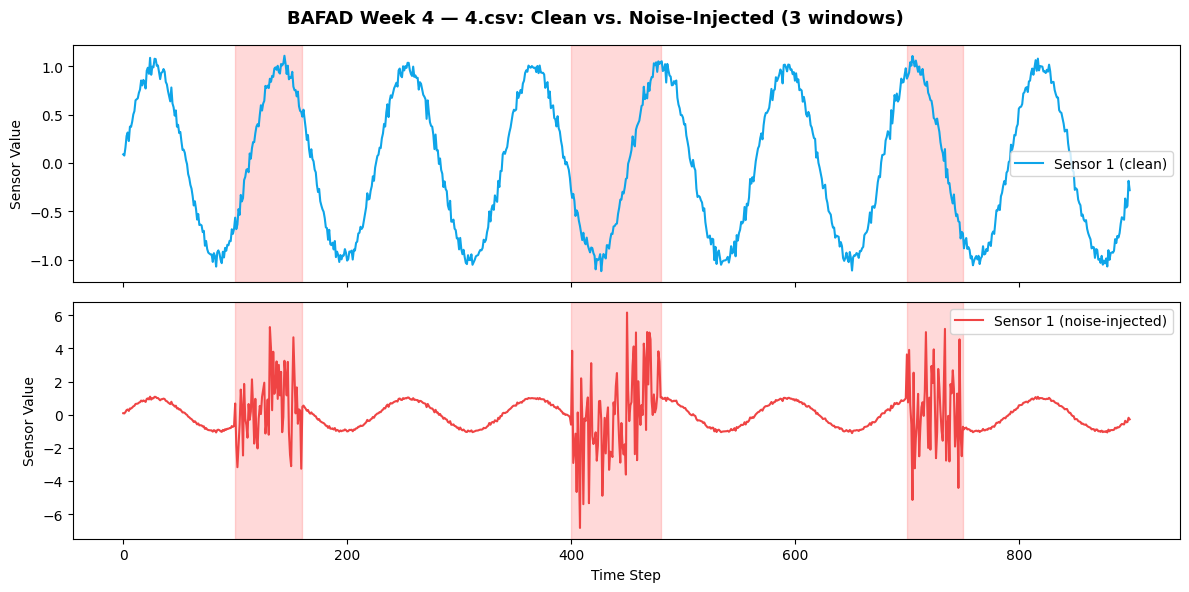

Plot saved to week04_exercise1_plot.png


In [10]:
# Process 4.csv for plotting
result_4 = process_skab_file(DATA_DIR / '4.csv', mode='noise', variance=2.5, seed=42)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
t = np.arange(result_4['n_rows'])

# TODO: Plot result_4['X_clean'][:, 0] on axes[0] (use color='#0EA5E9', label='Sensor 1 (clean)')
# TODO: Plot result_4['X_contaminated'][:, 0] on axes[1] (use color='#EF4444', label='Sensor 1 (noise-injected)')

# TODO: Add anomaly window shading to both panels (axvspan, alpha=0.15, color='red')
# TODO: Add ylabel, legend, and xlabel

# Plot clean signal
axes[0].plot(
    t,
    result_4['X_clean'][:, 0],
    color='#0EA5E9',
    label='Sensor 1 (clean)'
)

# Plot contaminated signal
axes[1].plot(
    t,
    result_4['X_contaminated'][:, 0],
    color='#EF4444',
    label='Sensor 1 (noise-injected)'
)

# Add anomaly window shading
for start, end in result_4['windows']:
    axes[0].axvspan(start, end, alpha=0.15, color='red')
    axes[1].axvspan(start, end, alpha=0.15, color='red')

# Labels and legends
axes[0].set_ylabel('Sensor Value')
axes[1].set_ylabel('Sensor Value')
axes[1].set_xlabel('Time Step')

axes[0].legend()
axes[1].legend()


fig.suptitle('BAFAD Week 4 — 4.csv: Clean vs. Noise-Injected (3 windows)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('week04_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to week04_exercise1_plot.png')

Q1. The pipeline calls np.random.seed(seed) inside process_skab_file() rather than once before the batch loop. Why does this matter? What would change if the seed were set once globally before the loop?

This is done so that way when the random variable is produced, then all the following SKAB files willhave the same random variable for consistant data.If this was not done, then each file would have a different random variable.

Q2. The catalog shows n_windows=0 for 3.csv. Should this file be excluded from anomaly detection evaluation? Explain both sides.

No. One could exclude it because it is not producing anomolies, but we could keep it to see if the anomoly detection model is avoiding false positive correctly.

Q3. A colleague runs batch_inject() again with mode='blackout' and saves the catalog as contamination_catalog_blackout.csv. How would you merge the two catalogs into one DataFrame that shows both modes for each file?

I would choose pd.concat() since both catalogs have the same structure and columns. We are looking for noise and blackouts and with pd.concat(), we would be able to ignore what we don't need and focus on the differences by combinging the two into a combined DataFrame.

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
